# 04. Scale Reliability, Demographic Segmentation & Risk Odds Analysis

## Objective
Extend the bivariate and OLS findings from Notebook 3 by validating the internal consistency of our composite distress scale, comparing high-risk subgroups across demographics and platforms, and estimating **Odds Ratios (OR)** for experiencing high mental distress.

## Analytical Modules
1. **Scale Reliability (Cronbach's $\alpha$):** Verify whether the 5 wellbeing items (`worries_score`, `concentration_diff`, `depression_score`, `interest_fluctuation`, `sleep_issues_score`) reliably measure a single underlying construct.
2. **Demographic Stratification:** Test whether mental distress and screen time differ significantly across `occupation` (University Students vs. Salaried Workers vs. School Students) and `gender`.
3. **Platform-Specific Comparison:** Compare `mental_distress_score` between users and non-users of specific platforms (e.g., TikTok, Instagram, Reddit, Discord).
4. **Logistic Regression (Odds Ratios):** Quantify how much each additional hour of screen time or unit of social comparison increases the odds of falling into the **High Mental Distress** group.


### Step 1: Load Processed Dataset & Configure Output Directory
Load `cleaned_wellbeing_data.csv` and configure output paths for subgroup and forest visualizations.


In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.dpi'] = 120

DATA_PATH = '../data/processed/cleaned_wellbeing_data.csv'
FIGURES_DIR = '../reports/figures/'
os.makedirs(FIGURES_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df)} records.")


Loaded 481 records.


### Step 2. Internal Consistency Reliability Check: Cronbach's Alpha ($\alpha$)
In survey statistics, combining multiple Likert items into a composite score (`mental_distress_score`) requires checking internal consistency. A Cronbach's $\alpha \ge 0.70$ indicates acceptable-to-good psychometric reliability.


In [2]:
def cronbach_alpha(items_df):
    items_df = items_df.dropna()
    k = items_df.shape[1]
    item_vars = items_df.var(axis=0, ddof=1).sum()
    total_var = items_df.sum(axis=1).var(ddof=1)
    alpha = (k / (k - 1)) * (1 - (item_vars / total_var))
    return alpha

wellbeing_items = [
    'worries_score',
    'concentration_diff',
    'depression_score',
    'interest_fluctuation',
    'sleep_issues_score'
]

alpha_val = cronbach_alpha(df[wellbeing_items])
print(f"Cronbach's Alpha for Composite Mental Distress Scale (5 items): alpha = {alpha_val:.4f}")


Cronbach's Alpha for Composite Mental Distress Scale (5 items): alpha = 0.7965


### Step 3: Demographic Stratification by Occupation (`05_distress_by_occupation.png`)
* **Key Takeaway:** Mental distress varies markedly by life stage and occupation:
  * **University Students:** Highest distress (Median = **18.0**, IQR: 15.0–21.0)
  * **School Students:** Moderate distress (Median = **16.0**, IQR: 13.0–20.0)
  * **Salaried Workers:** Lowest distress (Median = **14.0**, IQR: 10.0–17.25)


We test whether `mental_distress_score` and `daily_screen_time` differ significantly across `occupation` groups using the **Kruskal-Wallis H-test**, and visualize the distribution across groups.


Mental Distress across Occupations (['University Student', 'Salaried Worker', 'School Student']): H = 52.6382, p = 3.7133e-12


,n,median_distress,iqr_distress,mean_screen_time
occupation,,,,
Salaried Worker,132,14.0,7.25,2.55
School Student,49,16.0,7.00,3.79
University Student,292,18.0,6.00,3.73


C:\Users\ASUS\AppData\Local\Temp\ipykernel_3720\951679063.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_occ, x='occupation', y='mental_distress_score', palette='pastel')


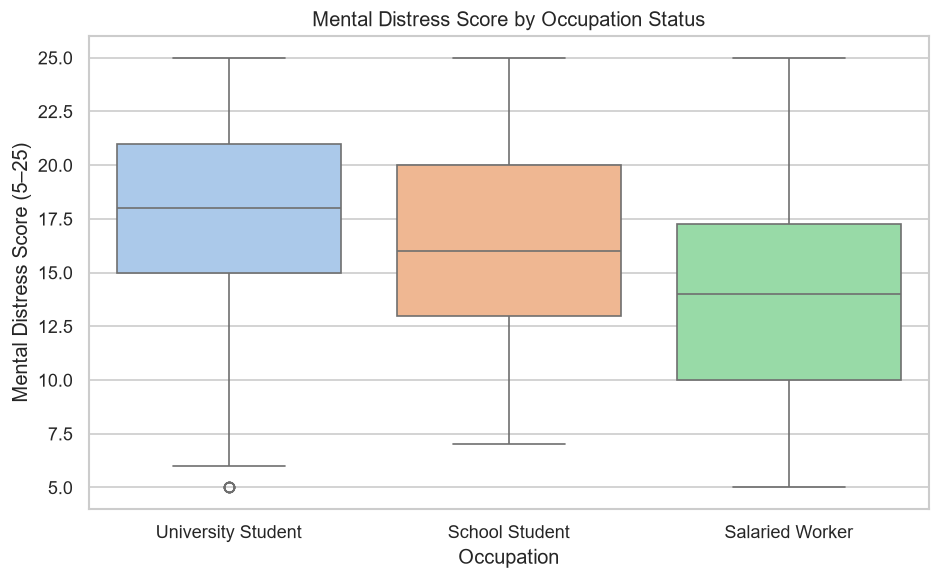

In [7]:
# Filter to major occupation categories with sufficient sample size (n >= 15)
occ_counts = df['occupation'].value_counts()
valid_occs = occ_counts[occ_counts >= 15].index.tolist()
sub_occ = df[df['occupation'].isin(valid_occs)]

occ_groups = [sub_occ[sub_occ['occupation'] == o]['mental_distress_score'] for o in valid_occs]
h_occ, p_occ = stats.kruskal(*occ_groups)
print(f"Mental Distress across Occupations ({valid_occs}): H = {h_occ:.4f}, p = {p_occ:.4e}")

# Summary table by occupation
occ_summary = sub_occ.groupby('occupation').agg(
    n=('mental_distress_score', 'count'),
    median_distress=('mental_distress_score', 'median'),
    iqr_distress=('mental_distress_score', lambda x: x.quantile(0.75) - x.quantile(0.25)),
    mean_screen_time=('daily_screen_time', 'mean')
).round(2)
display(occ_summary)

# Save grouped boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=sub_occ, x='occupation', y='mental_distress_score', palette='pastel')
plt.title('Mental Distress Score by Occupation Status')
plt.xlabel('Occupation')
plt.ylabel('Mental Distress Score (5–25)')
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}05_distress_by_occupation.png", bbox_inches='tight')
plt.show()


### Step 4: Platform-Specific Distress Comparisons
Respondents selected multiple platforms in `platforms`. Here, we test whether users of specific major platforms (Instagram, TikTok, Reddit, Discord, YouTube) report significantly different `mental_distress_score` medians compared to non-users.


In [5]:
target_platforms = ['Instagram', 'TikTok', 'Reddit', 'Discord', 'YouTube', 'Snapchat', 'Twitter']
platform_rows = []

for plat in target_platforms:
    is_user = df['platforms'].fillna('').str.contains(plat, case=False)
    users = df[is_user]['mental_distress_score']
    non_users = df[~is_user]['mental_distress_score']
    
    u_stat, p_val = stats.mannwhitneyu(users, non_users, alternative='two-sided')
    platform_rows.append({
        'Platform': plat,
        'Users_n': len(users),
        'User_Median': users.median(),
        'NonUser_Median': non_users.median(),
        'Diff': round(users.median() - non_users.median(), 2),
        'p-value': f"{p_val:.4e}",
        'Significant (alpha=0.05)': 'Yes' if p_val < 0.05 else 'No'
    })

display(pd.DataFrame(platform_rows).sort_values(by='Diff', ascending=False))


,Platform,Users_n,User_Median,NonUser_Median,Diff,p-value,Significant (alpha=0.05)
0,Instagram,359,18.0,14.0,4.0,2.2310e-06,Yes
1,TikTok,94,19.0,16.0,3.0,5.5700e-06,Yes
5,Snapchat,181,18.0,16.0,2.0,4.8132e-06,Yes
3,Discord,198,18.0,17.0,1.0,1.8494e-02,Yes
2,Reddit,126,17.0,17.0,0.0,5.6445e-01,No
4,YouTube,412,17.0,17.0,0.0,4.7325e-01,No
6,Twitter,131,17.0,17.0,0.0,4.5057e-01,No


### Step 5: Logistic Regression & Adjusted Odds Ratios (`06_odds_ratios_forest_plot.png`)
* **Model Setup:** Define **High Mental Distress** as scoring above the sample median (`mental_distress_score > 17`), and estimate Adjusted Odds Ratios (OR) with 95% confidence intervals.
* **Key Takeaway (Behavior Over Hours):**
  * **`social_comparison`** is the strongest risk factor (**OR ≈ 1.75**, 95% CI: ~1.49–2.07), meaning each 1-point increase in upward social comparison increases the odds of high distress by **~75%**.
  * **`restlessness`** (**OR ≈ 1.43**) and **`purposeless_use`** (**OR ≈ 1.41**) also significantly elevate risk.
  * **`daily_screen_time`** (**OR ≈ 1.16**, 95% CI crosses `1.0`) becomes statistically non-significant once behavioral habits are controlled—demonstrating that **psychological usage patterns, not raw screen hours alone, drive mental distress**.
  * **`age`** acts as a slight protective factor (**OR ≈ 0.95** per year).


High Distress Threshold: > 17.0 (Prevalence: 45.7%)

--- Adjusted Odds Ratios (95% CI) for High Mental Distress ---


,2.5%,97.5%,OR,p-value
daily_screen_time,0.990,1.361,1.160,0.067
purposeless_use,1.121,1.769,1.408,0.003
restlessness,1.180,1.738,1.432,0.000
social_comparison,1.485,2.069,1.753,0.000
age,0.923,0.976,0.949,0.000


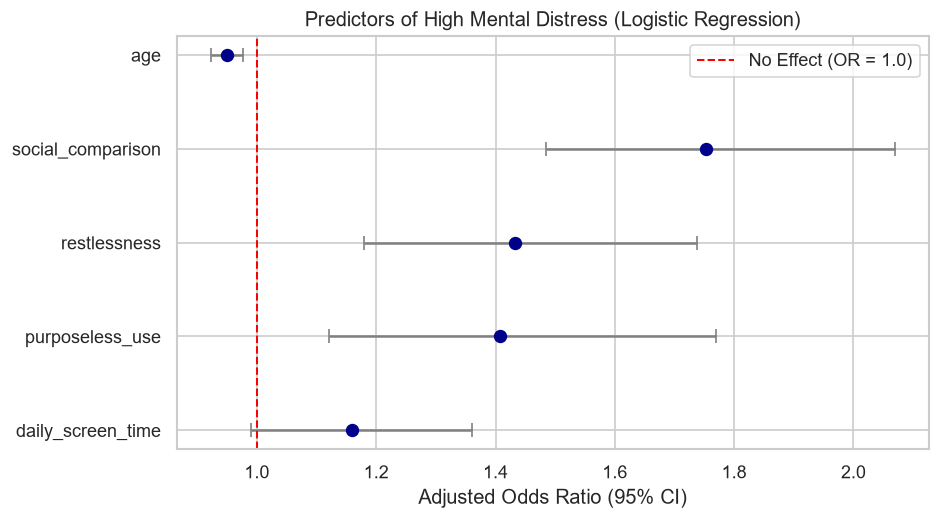

In [9]:
# 1. Create binary outcome: 1 = High Distress (above median), 0 = Low/Moderate Distress
median_threshold = df['mental_distress_score'].median()
df['high_distress'] = (df['mental_distress_score'] > median_threshold).astype(int)
print(f"High Distress Threshold: > {median_threshold} (Prevalence: {df['high_distress'].mean():.1%})\n")

# 2. Fit Logistic Regression
logit_formula = (
    "high_distress ~ daily_screen_time + purposeless_use + "
    "restlessness + social_comparison + age"
)
logit_model = smf.logit(formula=logit_formula, data=df).fit(disp=False)

# 3. Extract Odds Ratios and 95% Confidence Intervals
params = logit_model.params
conf = logit_model.conf_int()
conf['OR'] = params
conf.columns = ['2.5%', '97.5%', 'OR']
or_df = np.exp(conf)
or_df['p-value'] = logit_model.pvalues
or_df = or_df.drop('Intercept').round(3)

print("--- Adjusted Odds Ratios (95% CI) for High Mental Distress ---")
display(or_df)

# 4. Forest Plot of Odds Ratios
plt.figure(figsize=(8, 4.5))
y_pos = np.arange(len(or_df))
plt.errorbar(
    or_df['OR'], y_pos,
    xerr=[or_df['OR'] - or_df['2.5%'], or_df['97.5%'] - or_df['OR']],
    fmt='o', color='darkblue', ecolor='gray', capsize=4, markersize=7
)
plt.axvline(1.0, color='red', linestyle='--', linewidth=1.2, label='No Effect (OR = 1.0)')
plt.yticks(y_pos, or_df.index)
plt.xlabel('Adjusted Odds Ratio (95% CI)')
plt.title('Predictors of High Mental Distress (Logistic Regression)')
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}06_odds_ratios_forest_plot.png", bbox_inches='tight')
plt.show()
